# Curadoria e análise exploratória do dataset — Cenário 5

**Projeto:** coleta eficiente de pedidos de supermercado online
**Dataset:** Instacart Market Basket Analysis

## Objetivo deste notebook

Este notebook trata **apenas dos dados**: entende a estrutura dos arquivos do Instacart, verifica a qualidade e a integridade dos identificadores, integra as tabelas e caracteriza os pedidos. Ele **não assume nenhuma modelagem de grafo** (tipos de nó, arestas, pesos, camadas, layout da loja ou algoritmo de rota). Todo o conteúdo vale para qualquer modelagem que o grupo venha a adotar.

Ao final, teremos:

- uma visão geral dos arquivos e de suas colunas;
- verificações de qualidade e integridade dos identificadores;
- uma tabela integrada com pedidos, produtos, corredores e departamentos;
- caracterização dos pedidos (itens, corredores e departamentos por pedido), da frequência dos corredores, da coocorrência e da variação temporal;
- arquivos CSV curados, em formato neutro, para uso posterior.

## Índice

1. Importação das bibliotecas
2. Localização e carregamento dos arquivos
3. Conhecendo a estrutura do dataset
4. Curadoria e qualidade dos dados
5. Entendendo a divisão `eval_set`
6. Integração das tabelas
7. Análise dos produtos, corredores e departamentos
8. Análise dos pedidos
9. Frequência dos corredores e departamentos nos pedidos
10. Coocorrência entre corredores
11. Análise temporal dos pedidos
12. Análise dos clientes
13. Exportação dos dados curados
14. Conclusões da curadoria

**Terminologia.** No dataset, `aisle` é a categoria de localização do produto. Neste notebook usamos **aisle** (ou "corredor lógico"). Não se deve assumir que cada `aisle_id` equivale a um corredor físico independente de uma loja real: o dataset não traz layout físico.

## 1. Importação das bibliotecas

Pandas e NumPy para as tabelas, Matplotlib e Seaborn para os gráficos, SciPy (matriz esparsa) para a coocorrência e `Counter`/`itertools` para auxílio.

In [9]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import csr_matrix

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme()

## 2. Localização e carregamento dos arquivos

Coloque os CSVs na mesma pasta deste notebook ou ajuste `PASTA_DATASET`.

Arquivos esperados:

- `orders.csv`
- `products.csv`
- `order_products__train.csv`
- `order_products__prior.csv` (arquivo grande, ≈ 32 milhões de linhas)
- `aisles.csv`
- `departments.csv`

Os cinco arquivos menores são carregados aqui. O `prior` é carregado na seção 3.4, em blocos, por causa do tamanho.

In [10]:
PASTA_DATASET = Path("../dados/instacart")
USAR_PRIOR = True   # False => roda somente com o conjunto train (mais rápido, porém menos estável)

arquivos = {
    "orders": PASTA_DATASET / "orders.csv",
    "products": PASTA_DATASET / "products.csv",
    "order_products_train": PASTA_DATASET / "order_products__train.csv",
    "aisles": PASTA_DATASET / "aisles.csv",
    "departments": PASTA_DATASET / "departments.csv",
}
if USAR_PRIOR:
    arquivos["order_products_prior"] = PASTA_DATASET / "order_products__prior.csv"

arquivos_ausentes = [nome for nome, caminho in arquivos.items() if not caminho.exists()]
if arquivos_ausentes:
    raise FileNotFoundError(
        "Não encontrei estes arquivos: " + ", ".join(arquivos_ausentes)
        + ". Verifique PASTA_DATASET e os nomes dos CSVs."
    )

orders = pd.read_csv(arquivos["orders"])
produtos = pd.read_csv(arquivos["products"])
order_products = pd.read_csv(arquivos["order_products_train"])   # itens do conjunto train
aisles = pd.read_csv(arquivos["aisles"])
departamentos = pd.read_csv(arquivos["departments"])

print("Arquivos carregados (o prior será carregado na seção 3.4).")

Arquivos carregados (o prior será carregado na seção 3.4).


## 3. Conhecendo a estrutura do dataset

### 3.1. Dimensões das tabelas

In [3]:
tabelas = {
    "orders": orders,
    "products": produtos,
    "order_products__train": order_products,
    "aisles": aisles,
    "departments": departamentos,
}

resumo_dimensoes = pd.DataFrame([
    {"arquivo": nome, "quantidade_linhas": t.shape[0], "quantidade_colunas": t.shape[1]}
    for nome, t in tabelas.items()
])
display(resumo_dimensoes)

,arquivo,quantidade_linhas,quantidade_colunas
0,orders,3421083,7
1,products,49688,4
2,order_products__train,1384617,4
3,aisles,134,2
4,departments,21,2


### 3.2. Colunas, tipos e amostras

In [4]:
for nome, tabela in tabelas.items():
    print(f"\n--- {nome} ---")
    display(tabela.head())
    print(tabela.dtypes)


--- orders ---


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0
3,2254736,1,prior,4,4,7,29.0
4,431534,1,prior,5,4,15,28.0


order_id                    int64
user_id                     int64
eval_set                      str
order_number                int64
order_dow                   int64
order_hour_of_day           int64
days_since_prior_order    float64
dtype: object

--- products ---


,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13


product_id       int64
product_name       str
aisle_id         int64
department_id    int64
dtype: object

--- order_products__train ---


,order_id,product_id,add_to_cart_order,reordered
0,1,49302,1,1
1,1,11109,2,1
2,1,10246,3,0
3,1,49683,4,0
4,1,43633,5,1


order_id             int64
product_id           int64
add_to_cart_order    int64
reordered            int64
dtype: object

--- aisles ---


,aisle_id,aisle
0,1,prepared soups salads
1,2,specialty cheeses
2,3,energy granola bars
3,4,instant foods
4,5,marinades meat preparation


aisle_id    int64
aisle         str
dtype: object

--- departments ---


,department_id,department
0,1,frozen
1,2,other
2,3,bakery
3,4,produce
4,5,alcohol


department_id    int64
department         str
dtype: object


### 3.3. Significado das principais colunas

| Arquivo | Colunas relevantes | Significado |
|---|---|---|
| `orders.csv` | `order_id`, `user_id`, `eval_set`, `order_number`, `order_dow`, `order_hour_of_day`, `days_since_prior_order` | Pedido, cliente, divisão do dataset, número sequencial do pedido do cliente, dia, hora e intervalo desde o pedido anterior |
| `order_products__*.csv` | `order_id`, `product_id`, `add_to_cart_order`, `reordered` | Produtos de cada pedido, ordem de inclusão no carrinho e indicação de recompra |
| `products.csv` | `product_id`, `product_name`, `aisle_id`, `department_id` | Cadastro do produto e suas categorias |
| `aisles.csv` | `aisle_id`, `aisle` | Identificador e nome do corredor lógico/categoria do Instacart |
| `departments.csv` | `department_id`, `department` | Identificador e nome do departamento |

**Atenção:** `add_to_cart_order` é a ordem em que o cliente colocou o item no carrinho online, **não** a ordem de coleta em uma loja.

### 3.4. O que é o `order_products__prior.csv`?

**Estrutura:** idêntica à do `train`. Cada linha é um produto dentro de um pedido: `order_id`, `product_id`, `add_to_cart_order` (posição em que o produto foi colocado no carrinho) e `reordered` (1 se o cliente já havia comprado esse produto antes).

**A diferença está em *quais pedidos* cada arquivo contém.** O `orders.csv` tem a coluna `eval_set`. No desafio original do Instacart, para cada cliente o **último pedido foi separado** e todos os anteriores formam o histórico:

| `eval_set` | Pedidos | O que é | Onde estão os itens |
|---|---|---|---|
| `prior` | 3.214.874 | Histórico: todos os pedidos *anteriores* ao último de cada cliente | `order_products__prior.csv` |
| `train` | 131.209 | Último pedido de parte dos clientes, com itens revelados | `order_products__train.csv` |
| `test` | 75.000 | Último pedido dos demais clientes, com itens **escondidos** | em nenhum arquivo |

Consequências:

- `prior` e `train` têm `order_id` **disjuntos** (verificado na seção 4.5), mas os **clientes são os mesmos**.
- Os pedidos `test` aparecem em `orders.csv`, mas não têm produtos. Não servem para análises de itens.
- O `prior` é cerca de 20 vezes maior que o `train`. Com `prior` + `train` temos ≈ 3,35 milhões de pedidos com itens conhecidos; o `train` sozinho cobre só ≈ 4%.

**Como lidamos com o tamanho:** o arquivo é lido em blocos. Em cada bloco trazemos o `aisle_id` do produto por busca em vetor (sem `merge` com texto) e guardamos apenas `order_id`, `product_id`, `aisle_id` e `reordered`, em tipos compactos.

In [5]:
CAT_EVAL = pd.CategoricalDtype(["prior", "train", "test"])
MAX_PRODUCT_ID = produtos["product_id"].max()

# vetor de busca: lookup_aisle[product_id] -> aisle_id (0 = produto sem cadastro)
lookup_aisle = np.zeros(MAX_PRODUCT_ID + 1, dtype=np.int16)
lookup_aisle[produtos["product_id"].to_numpy()] = produtos["aisle_id"].to_numpy()
ids_pedidos_orders = pd.Index(orders["order_id"])


def enxugar_itens(df, eval_set):
    """Reduz uma tabela de itens às colunas necessárias, com tipos compactos."""
    pid = df["product_id"].to_numpy()
    validos = pid <= MAX_PRODUCT_ID
    aisle = np.zeros(len(df), dtype=np.int16)
    aisle[validos] = lookup_aisle[pid[validos]]
    return pd.DataFrame({
        "order_id": df["order_id"].astype("int32").to_numpy(),
        "product_id": df["product_id"].astype("int32").to_numpy(),
        "aisle_id": aisle,
        "reordered": df["reordered"].astype("int8").to_numpy(),
        "eval_set": pd.Series(eval_set, index=range(len(df)), dtype=CAT_EVAL),
    })


def carregar_itens_em_blocos(caminho, eval_set, tamanho_bloco=4_000_000):
    """Lê o CSV em blocos, confere a qualidade de cada bloco e devolve a tabela enxuta + estatísticas."""
    blocos = []
    stats = {"linhas": 0, "valores_ausentes": 0, "produtos_sem_cadastro": 0,
             "pedidos_fora_do_orders_csv": 0, "reordered_diferente_de_0_ou_1": 0}
    for bloco in pd.read_csv(caminho, chunksize=tamanho_bloco):
        stats["linhas"] += len(bloco)
        stats["valores_ausentes"] += int(bloco.isna().sum().sum())
        stats["reordered_diferente_de_0_ou_1"] += int((~bloco["reordered"].isin([0, 1])).sum())
        enx = enxugar_itens(bloco, eval_set)
        stats["produtos_sem_cadastro"] += int((enx["aisle_id"] == 0).sum())
        stats["pedidos_fora_do_orders_csv"] += int((~enx["order_id"].isin(ids_pedidos_orders)).sum())
        blocos.append(enx)
    return pd.concat(blocos, ignore_index=True), stats


# train (já está em memória) no formato enxuto
itens_train = enxugar_itens(order_products, "train")

if USAR_PRIOR:
    itens_prior, stats_prior = carregar_itens_em_blocos(arquivos["order_products_prior"], "prior")
    print(f"prior carregado: {len(itens_prior):,} linhas | "
          f"{itens_prior.memory_usage(deep=True).sum() / 1e6:,.0f} MB em memória")
else:
    itens_prior, stats_prior = None, None
    print("USAR_PRIOR = False: prior não foi carregado.")

prior carregado: 32,434,489 linhas | 389 MB em memória


## 4. Curadoria e qualidade dos dados

Antes de unir as tabelas, verificamos duplicidades, valores ausentes e unicidade das chaves. **Nada é removido automaticamente**: primeiro identificamos o problema e avaliamos sua causa.

### 4.1. Valores ausentes

In [6]:
relatorio_ausentes = pd.DataFrame({nome: t.isna().sum() for nome, t in tabelas.items()}).fillna(0).astype(int)
display(relatorio_ausentes)

,orders,products,order_products__train,aisles,departments
add_to_cart_order,0,0,0,0,0
aisle,0,0,0,0,0
aisle_id,0,0,0,0,0
days_since_prior_order,206209,0,0,0,0
department,0,0,0,0,0
department_id,0,0,0,0,0
eval_set,0,0,0,0,0
order_dow,0,0,0,0,0
order_hour_of_day,0,0,0,0,0
order_id,0,0,0,0,0


**Interpretação:** valores ausentes em `days_since_prior_order` ocorrem quando não existe pedido anterior do cliente (primeiro pedido). Não devem ser preenchidos com zero. Ausências em identificadores ou nomes usados nos relacionamentos precisam ser investigadas antes da integração.

### 4.2. Registros duplicados

In [11]:
relatorio_duplicados = pd.DataFrame([
    {"arquivo": nome, "linhas_duplicadas_completas": int(t.duplicated().sum())}
    for nome, t in tabelas.items()
])
display(relatorio_duplicados)

chaves_primarias = {
    "orders": (orders, "order_id"),
    "products": (produtos, "product_id"),
    "aisles": (aisles, "aisle_id"),
    "departments": (departamentos, "department_id"),
}
for nome, (tabela, coluna) in chaves_primarias.items():
    print(f"{nome}: {tabela[coluna].duplicated().sum()} valores duplicados em {coluna}; "
          f"{tabela[coluna].isna().sum()} valores ausentes.")

print("\nPares order_id + product_id duplicados no train:",
      order_products.duplicated(subset=["order_id", "product_id"]).sum())

,arquivo,linhas_duplicadas_completas
0,orders,0
1,products,0
2,order_products__train,0
3,aisles,0
4,departments,0


orders: 0 valores duplicados em order_id; 0 valores ausentes.
products: 0 valores duplicados em product_id; 0 valores ausentes.
aisles: 0 valores duplicados em aisle_id; 0 valores ausentes.
departments: 0 valores duplicados em department_id; 0 valores ausentes.

Pares order_id + product_id duplicados no train: 0


### 4.3. Verificação dos identificadores entre arquivos

In [12]:
print("Produtos de order_products (train) sem cadastro:", (~order_products["product_id"].isin(produtos["product_id"])).sum())
print("Pedidos de order_products (train) sem cadastro em orders:", (~order_products["order_id"].isin(orders["order_id"])).sum())
print("aisle_id de products sem cadastro em aisles:", (~produtos["aisle_id"].isin(aisles["aisle_id"])).sum())
print("department_id de products sem cadastro em departments:", (~produtos["department_id"].isin(departamentos["department_id"])).sum())

Produtos de order_products (train) sem cadastro: 0
Pedidos de order_products (train) sem cadastro em orders: 0
aisle_id de products sem cadastro em aisles: 0
department_id de products sem cadastro em departments: 0


### 4.4. Relação entre aisle (corredor lógico/seção) e departamento

Cada `aisle_id` deve estar associado a um único `department_id` no cadastro de produtos. A consulta abaixo identifica exceções.

In [13]:
departamentos_por_aisle = produtos.groupby("aisle_id")["department_id"].nunique()
excecoes = departamentos_por_aisle[departamentos_por_aisle > 1]
print("Aisles associados a mais de um departamento:", len(excecoes))
display(excecoes)

Aisles associados a mais de um departamento: 0


Series([], Name: department_id, dtype: int64)

### 4.5. Qualidade do conjunto `prior`

Repetimos para o `prior` as mesmas verificações feitas no `train` e acrescentamos duas específicas:

- os pedidos do `prior` devem ter `eval_set == "prior"` em `orders.csv`;
- `prior` e `train` não devem compartilhar nenhum `order_id`;
- todos os pedidos `prior` de `orders.csv` devem ter itens no arquivo.

In [14]:
if USAR_PRIOR:
    print("Estatísticas de leitura do prior (por tipo de problema):")
    display(pd.Series(stats_prior, name="prior").to_frame())

    print("Pares order_id + product_id duplicados no prior:",
          itens_prior.duplicated(subset=["order_id", "product_id"]).sum())

    ids_prior = pd.Index(itens_prior["order_id"].unique())
    ids_train = pd.Index(itens_train["order_id"].unique())

    eval_dos_pedidos_prior = orders.set_index("order_id")["eval_set"].reindex(ids_prior)
    print("\neval_set (em orders.csv) dos pedidos que aparecem no arquivo prior:")
    display(eval_dos_pedidos_prior.value_counts(dropna=False))

    print("Pedidos em comum entre prior e train:", len(ids_prior.intersection(ids_train)))

    pedidos_prior_orders = orders.loc[orders["eval_set"] == "prior", "order_id"]
    print("Pedidos prior de orders.csv SEM itens no arquivo:", int((~pedidos_prior_orders.isin(ids_prior)).sum()))
else:
    print("USAR_PRIOR = False: verificação do prior ignorada.")

Estatísticas de leitura do prior (por tipo de problema):


,prior
linhas,32434489
valores_ausentes,0
produtos_sem_cadastro,0
pedidos_fora_do_orders_csv,0
reordered_diferente_de_0_ou_1,0


Pares order_id + product_id duplicados no prior: 0

eval_set (em orders.csv) dos pedidos que aparecem no arquivo prior:


eval_set
prior    3214874
Name: count, dtype: int64

Pedidos em comum entre prior e train: 0
Pedidos prior de orders.csv SEM itens no arquivo: 0


## 5. Entendendo a divisão `eval_set`

A coluna `eval_set` indica a divisão do desafio original a que cada pedido pertence. Ela **não** é uma característica do supermercado.

- `prior`: itens em `order_products__prior.csv`.
- `train`: itens em `order_products__train.csv`.
- `test`: aparece em `orders.csv`, mas **sem itens em nenhum arquivo**.

Ter um pedido em `orders.csv` não garante ter seus produtos. Para análises de itens usamos apenas `prior` e `train`.

In [15]:
print("Valores encontrados em eval_set:")
display(orders["eval_set"].value_counts(dropna=False))

print("\nDivisão dos pedidos presentes em order_products__train:")
display(orders.loc[orders["order_id"].isin(order_products["order_id"]), "eval_set"].value_counts(dropna=False))

Valores encontrados em eval_set:


eval_set
prior    3214874
train     131209
test       75000
Name: count, dtype: int64


Divisão dos pedidos presentes em order_products__train:


eval_set
train    131209
Name: count, dtype: int64

### 5.1. Como `prior`, `train` e `test` se relacionam com os clientes

Se a explicação da seção 3.4 estiver correta, então:

- o último pedido (maior `order_number`) de cada cliente deve ser `train` ou `test`, nunca `prior`;
- o número de clientes deve ser igual ao número de `NaN` em `days_since_prior_order`, pois o primeiro pedido de cada cliente não tem pedido anterior.

In [16]:
ultimo_pedido_por_cliente = orders.loc[orders.groupby("user_id")["order_number"].idxmax()]

print("eval_set do ÚLTIMO pedido de cada cliente:")
display(ultimo_pedido_por_cliente["eval_set"].value_counts())

print("Clientes distintos:", orders["user_id"].nunique())
print("NaN em days_since_prior_order:", int(orders["days_since_prior_order"].isna().sum()))

eval_set do ÚLTIMO pedido de cada cliente:


eval_set
train    131209
test      75000
Name: count, dtype: int64

Clientes distintos: 206209
NaN em days_since_prior_order: 206209


## 6. Integração das tabelas

### 6.1. Tabela integrada completa (somente `train`)

Uma linha por produto dentro de um pedido `train`. Usamos `left join` para preservar os itens e `validate="many_to_one"` para checar que cada identificador aponta para no máximo um cadastro.

In [17]:
dados = (
    order_products
    .merge(produtos, on="product_id", how="left", validate="many_to_one")
    .merge(aisles, on="aisle_id", how="left", validate="many_to_one")
    .merge(departamentos, on="department_id", how="left", validate="many_to_one")
    .merge(orders, on="order_id", how="left", validate="many_to_one")
)

colunas_dados = [
    "order_id", "user_id", "product_id", "product_name", "aisle_id", "aisle",
    "department_id", "department", "add_to_cart_order", "reordered",
    "order_dow", "order_hour_of_day", "days_since_prior_order",
]
dados = dados[colunas_dados].copy()

print("Dimensões da tabela integrada:", dados.shape)
display(dados.head())

print("\nValores ausentes após a integração:")
display(dados.isna().sum().rename("valores_ausentes").to_frame())

Dimensões da tabela integrada: (1384617, 13)


,order_id,user_id,product_id,product_name,aisle_id,aisle,department_id,department,add_to_cart_order,reordered,order_dow,order_hour_of_day,days_since_prior_order
0,1,112108,49302,Bulgarian Yogurt,120,yogurt,16,dairy eggs,1,1,4,10,9.0
1,1,112108,11109,Organic 4% Milk Fat Whole Milk Cottage Cheese,108,other creams cheeses,16,dairy eggs,2,1,4,10,9.0
2,1,112108,10246,Organic Celery Hearts,83,fresh vegetables,4,produce,3,0,4,10,9.0
3,1,112108,49683,Cucumber Kirby,83,fresh vegetables,4,produce,4,0,4,10,9.0
4,1,112108,43633,Lightly Smoked Sardines in Olive Oil,95,canned meat seafood,15,canned goods,5,1,4,10,9.0



Valores ausentes após a integração:


,valores_ausentes
order_id,0
user_id,0
product_id,0
product_name,0
aisle_id,0
aisle,0
department_id,0
department,0
add_to_cart_order,0
reordered,0


Em `days_since_prior_order` os `NaN` são esperados (primeiro pedido do cliente). Qualquer outra coluna com ausências indica relacionamento sem correspondência.

### 6.2. Tabela enxuta com `prior` + `train`

A tabela `dados` só vale para o `train` (≈ 1,4 milhão de linhas). Fazer o mesmo `merge` com textos para ≈ 33 milhões de linhas seria inviável. Para as análises em escala usamos `itens`: uma linha por produto dentro de um pedido, para `prior` **e** `train`, com `eval_set` indicando a origem.

Também criamos `lookup_depto`, um vetor `aisle_id → department_id` (informação do cadastro de produtos, verificada na seção 4.4).

In [18]:
itens = pd.concat([itens_prior, itens_train], ignore_index=True) if USAR_PRIOR else itens_train

print("Dimensões de itens:", itens.shape)
print(f"Memória: {itens.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
print("\nLinhas por conjunto:")
display(itens["eval_set"].value_counts())
display(itens.head())

# aisle -> departamento (cadastro do dataset)
aisle_depto = produtos[["aisle_id", "department_id"]].drop_duplicates()
if not aisle_depto["aisle_id"].is_unique:
    raise ValueError("Há aisles ligados a mais de um departamento. Revise a seção 4.4.")

lookup_depto = np.zeros(aisles["aisle_id"].max() + 1, dtype=np.int16)
lookup_depto[aisle_depto["aisle_id"].to_numpy()] = aisle_depto["department_id"].to_numpy()

Dimensões de itens: (33819106, 5)
Memória: 406 MB

Linhas por conjunto:


eval_set
prior    32434489
train     1384617
test            0
Name: count, dtype: int64

,order_id,product_id,aisle_id,reordered,eval_set
0,2,33120,86,1,prior
1,2,28985,83,1,prior
2,2,9327,104,0,prior
3,2,45918,19,1,prior
4,2,30035,17,0,prior


## 7. Análise dos produtos, aisles e departamentos

### 7.1. Produtos cadastrados por aisle

Conta quantos produtos diferentes estão cadastrados em cada `aisle_id`. **Não** representa a quantidade de itens coletados em um pedido.

In [19]:
quantidade_por_aisle = (
    produtos.groupby("aisle_id")["product_id"].nunique().reset_index(name="quantidade_produtos")
    .merge(aisles, on="aisle_id", how="left", validate="one_to_one")
    .merge(aisle_depto.merge(departamentos, on="department_id"), on="aisle_id", how="left", validate="one_to_one")
    .sort_values("quantidade_produtos", ascending=False)
)
display(quantidade_por_aisle.head(20))
print("Média de produtos cadastrados por aisle:", round(quantidade_por_aisle["quantidade_produtos"].mean(), 1))

,aisle_id,quantidade_produtos,aisle,department_id,department
99,100,1258,missing,21,missing
44,45,1246,candy chocolate,19,snacks
36,37,1091,ice cream ice,1,frozen
46,47,1038,vitamins supplements,11,personal care
119,120,1026,yogurt,16,dairy eggs
106,107,989,chips pretzels,19,snacks
93,94,894,tea,7,beverages
20,21,891,packaged cheese,16,dairy eggs
37,38,880,frozen meals,1,frozen
60,61,874,cookies cakes,19,snacks


Média de produtos cadastrados por aisle: 370.8


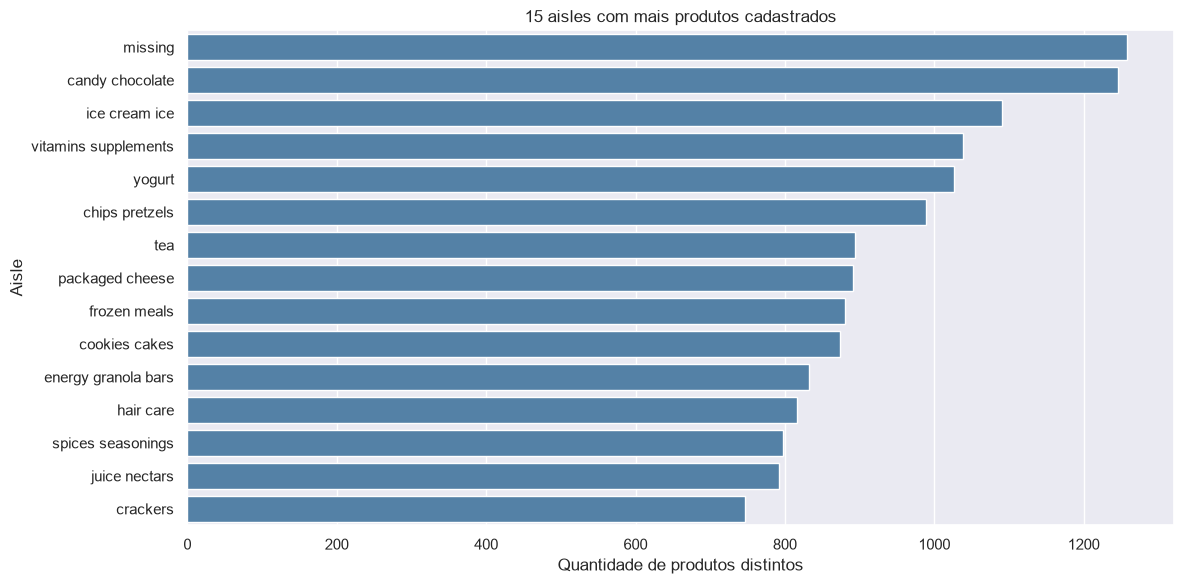

In [20]:
plt.figure(figsize=(12, 6))
sns.barplot(data=quantidade_por_aisle.head(15), x="quantidade_produtos", y="aisle", color="steelblue")
plt.title("15 aisles com mais produtos cadastrados")
plt.xlabel("Quantidade de produtos distintos")
plt.ylabel("Aisle")
plt.tight_layout()
plt.show()

### 7.2. Produtos e aisles por departamento

In [21]:
quantidade_por_departamento = (
    produtos.groupby("department_id")
    .agg(quantidade_produtos=("product_id", "nunique"), quantidade_aisles=("aisle_id", "nunique"))
    .reset_index()
    .merge(departamentos, on="department_id", how="left", validate="one_to_one")
    .sort_values("quantidade_produtos", ascending=False)
)
display(quantidade_por_departamento)

,department_id,quantidade_produtos,quantidade_aisles,department
10,11,6563,17,personal care
18,19,6264,11,snacks
12,13,5371,12,pantry
6,7,4365,8,beverages
0,1,4007,11,frozen
15,16,3449,10,dairy eggs
16,17,3085,10,household
14,15,2092,5,canned goods
8,9,1858,5,dry goods pasta
3,4,1684,5,produce


### 7.3. Produtos mais pedidos e taxa de recompra

Aqui usamos os itens efetivamente pedidos (`prior` + `train`).

In [22]:
contagem_produtos = itens.groupby("product_id").agg(
    vezes_pedido=("order_id", "size"),
    taxa_recompra=("reordered", "mean"),
).reset_index()

produtos_mais_pedidos = (
    contagem_produtos.merge(produtos, on="product_id", how="left", validate="one_to_one")
    .merge(aisles, on="aisle_id", how="left")
    .sort_values("vezes_pedido", ascending=False)
    .reset_index(drop=True)
)
produtos_mais_pedidos["taxa_recompra"] = produtos_mais_pedidos["taxa_recompra"].round(3)

print("Produtos cadastrados que nunca foram pedidos:", len(produtos) - len(contagem_produtos))
display(produtos_mais_pedidos[["product_id", "product_name", "aisle", "vezes_pedido", "taxa_recompra"]].head(20))

pareto = produtos_mais_pedidos["vezes_pedido"].cumsum() / produtos_mais_pedidos["vezes_pedido"].sum()
for k in [100, 1000, 5000]:
    if k <= len(pareto):
        print(f"Os {k:,} produtos mais pedidos concentram {100 * pareto.iloc[k - 1]:.1f}% dos itens")

Produtos cadastrados que nunca foram pedidos: 3


,product_id,product_name,aisle,vezes_pedido,taxa_recompra
0,24852,Banana,fresh fruits,491291,0.845
1,13176,Bag of Organic Bananas,fresh fruits,394930,0.834
2,21137,Organic Strawberries,fresh fruits,275577,0.778
3,21903,Organic Baby Spinach,packaged vegetables fruits,251705,0.774
4,47209,Organic Hass Avocado,fresh fruits,220877,0.798
5,47766,Organic Avocado,fresh fruits,184224,0.761
6,47626,Large Lemon,fresh fruits,160792,0.698
7,16797,Strawberries,fresh fruits,149445,0.700
8,26209,Limes,fresh fruits,146660,0.682
9,27845,Organic Whole Milk,milk,142813,0.831


Os 100 produtos mais pedidos concentram 23.1% dos itens
Os 1,000 produtos mais pedidos concentram 53.9% dos itens
Os 5,000 produtos mais pedidos concentram 81.5% dos itens


## 8. Análise dos pedidos

A unidade de análise passa a ser o pedido, usando **todos** os pedidos com itens conhecidos (`prior` + `train`). Calculamos:

- quantidade de itens no pedido;
- quantidade de aisles distintos;
- quantidade de departamentos distintos;
- dia e horário do pedido.

Aisles e departamentos distintos são contados por pares únicos (`order_id`, `aisle_id`) e (`order_id`, `department_id`), de modo que vários produtos do mesmo aisle contam como uma única ocorrência.

In [23]:
# oa = um registro por (pedido, aisle); od = um registro por (pedido, departamento)
oa = itens[["order_id", "aisle_id", "eval_set"]].drop_duplicates()

od = pd.DataFrame({
    "order_id": oa["order_id"].to_numpy(),
    "department_id": lookup_depto[oa["aisle_id"].to_numpy()],
    "eval_set": oa["eval_set"].array,
}).drop_duplicates()

qtd_itens = itens.groupby("order_id").size().rename("quantidade_itens")
qtd_aisles = oa.groupby("order_id").size().rename("quantidade_aisles")
qtd_deptos = od.groupby("order_id").size().rename("quantidade_departamentos")

pedidos = (
    pd.concat([qtd_itens, qtd_aisles, qtd_deptos], axis=1)
    .reset_index()
    .merge(
        orders[["order_id", "user_id", "eval_set", "order_dow", "order_hour_of_day"]],
        on="order_id", how="left", validate="one_to_one",
    )
    .rename(columns={"order_dow": "dia_semana", "order_hour_of_day": "horario"})
)

display(pedidos.head())
print("Quantidade de pedidos com itens disponíveis:", len(pedidos))
display(pedidos["eval_set"].value_counts())

,order_id,quantidade_itens,quantidade_aisles,quantidade_departamentos,user_id,eval_set,dia_semana,horario
0,1,8,6,3,112108,train,4,10
1,2,9,8,3,202279,prior,5,9
2,3,8,6,4,205970,prior,5,17
3,4,13,9,5,178520,prior,1,9
4,5,26,19,11,156122,prior,6,16


Quantidade de pedidos com itens disponíveis: 3346083


eval_set
prior    3214874
train     131209
Name: count, dtype: int64

### 8.1. Lista de aisles e departamentos por pedido (somente `train`)

Guardar uma lista por pedido para 3,3 milhões de pedidos consome muita memória, e as análises agregadas não precisam dela. Montamos as listas apenas para os pedidos `train` (≈ 131 mil), que ficam disponíveis como tabela "um pedido por linha" para uso posterior.

In [24]:
def listas_por_pedido(df, coluna, eval_set):
    return (
        df[df["eval_set"] == eval_set]
        .groupby("order_id", observed=True)[coluna]
        .agg(lambda v: sorted(v.tolist()))
    )

aisles_por_pedido_train = listas_por_pedido(oa, "aisle_id", "train").rename("aisles")
deptos_por_pedido_train = listas_por_pedido(od, "department_id", "train").rename("departamentos")

pedidos_train = (
    pedidos[pedidos["eval_set"] == "train"]
    .merge(aisles_por_pedido_train, on="order_id", validate="one_to_one")
    .merge(deptos_por_pedido_train, on="order_id", validate="one_to_one")
    .reset_index(drop=True)
)
display(pedidos_train.head())
print("Pedidos train com lista de aisles e departamentos:", len(pedidos_train))

,order_id,quantidade_itens,quantidade_aisles,quantidade_departamentos,user_id,eval_set,dia_semana,horario,aisles,departamentos
0,1,8,6,3,112108,train,4,10,"[21, 24, 83, 95, 108, 120]","[4, 15, 16]"
1,36,8,7,4,79431,train,6,18,"[2, 53, 83, 86, 96, 115, 123]","[4, 7, 16, 20]"
2,38,9,6,4,42756,train,6,16,"[16, 19, 83, 116, 117, 123]","[1, 4, 13, 19]"
3,96,7,4,3,17227,train,6,20,"[83, 96, 116, 123]","[1, 4, 20]"
4,98,49,35,12,56463,train,3,8,"[2, 16, 17, 19, 21, 24, 25, 31, 34, 36, 37, 54...","[1, 3, 4, 7, 11, 12, 13, 15, 16, 17, 19, 20]"


Pedidos train com lista de aisles e departamentos: 131209


### 8.2. Estatísticas descritivas dos pedidos

In [25]:
colunas_tam = ["quantidade_itens", "quantidade_aisles", "quantidade_departamentos"]

print("Todos os pedidos (prior + train):")
display(pedidos[colunas_tam].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(2))

print("\nPor conjunto:")
display(pedidos.groupby("eval_set", observed=True)[colunas_tam].agg(["count", "mean", "median", "std", "max"]).round(2))

Todos os pedidos (prior + train):


,quantidade_itens,quantidade_aisles,quantidade_departamentos
count,3346083.00,3346083.00,3346083.00
mean,10.11,7.27,4.74
std,7.54,4.77,2.55
min,1.00,1.00,1.00
5%,2.00,1.00,1.00
25%,5.00,4.00,3.00
50%,8.00,6.00,4.00
75%,14.00,10.00,6.00
95%,25.00,16.00,9.00
max,145.00,57.00,18.00



Por conjunto:


quantidade_itens                          quantidade_aisles        \
                    count   mean median   std  max             count  mean   
eval_set                                                                     
prior             3214874  10.09    8.0  7.53  145           3214874  7.26   
train              131209  10.55    9.0  7.93   80            131209  7.55   

                          quantidade_departamentos                         
         median   std max                    count  mean median   std max  
eval_set                                                                   
prior       6.0  4.76  57                  3214874  4.74    4.0  2.55  18  
train       7.0  5.00  44                   131209  4.88    5.0  2.64  16

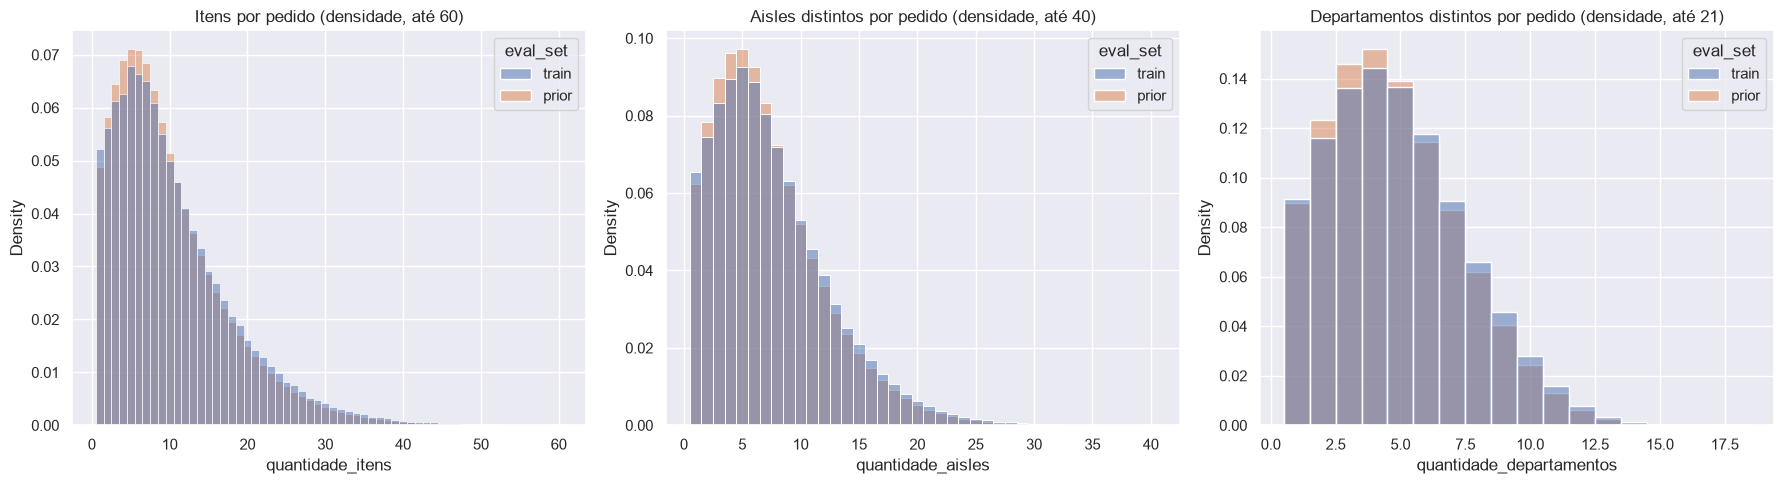

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, coluna, titulo, limite in zip(
    axes, colunas_tam,
    ["Itens por pedido", "Aisles distintos por pedido", "Departamentos distintos por pedido"],
    [60, 40, 21],
):
    sns.histplot(
        data=pedidos[pedidos[coluna] <= limite], x=coluna, hue="eval_set",
        stat="density", common_norm=False, discrete=True, ax=ax,
    )
    ax.set_title(f"{titulo} (densidade, até {limite})")
plt.tight_layout()
plt.show()

### 8.3. Relação entre itens e aisles distintos

Em um pedido com muitos itens, os itens tendem a se repetir nos mesmos aisles. Esta razão mostra o quanto o número de aisles cresce mais devagar que o número de itens.

In [27]:
pedidos["itens_por_aisle"] = pedidos["quantidade_itens"] / pedidos["quantidade_aisles"]
print("Itens por aisle distinto (média):", round(pedidos["itens_por_aisle"].mean(), 2))
print("Correlação itens x aisles distintos (Spearman):",
      round(pedidos["quantidade_itens"].corr(pedidos["quantidade_aisles"], method="spearman"), 3))

faixas = pd.cut(pedidos["quantidade_itens"], bins=[0, 5, 10, 15, 20, 30, 50, 200], right=True)
display(
    pedidos.groupby(faixas, observed=True)[["quantidade_aisles", "quantidade_departamentos"]]
    .agg(["mean", "median"]).round(2)
)

Itens por aisle distinto (média): 1.37
Correlação itens x aisles distintos (Spearman): 0.943


quantidade_aisles        quantidade_departamentos       
                              mean median                     mean median
quantidade_itens                                                         
(0, 5]                        2.77    3.0                     2.30    2.0
(5, 10]                       6.16    6.0                     4.42    4.0
(10, 15]                      9.25    9.0                     5.96    6.0
(15, 20]                     12.09   12.0                     7.19    7.0
(20, 30]                     15.54   16.0                     8.50    9.0
(30, 50]                     20.94   21.0                    10.13   10.0
(50, 200]                    28.52   29.0                    11.62   12.0

### 8.4. Pedidos com maior quantidade de aisles

In [28]:
display(pedidos.sort_values(["quantidade_aisles", "quantidade_itens"], ascending=False).head(20))

,order_id,quantidade_itens,quantidade_aisles,quantidade_departamentos,user_id,eval_set,dia_semana,horario,itens_por_aisle
2905258,2970392,121,57,15,79738,prior,4,12,2.122807
590926,604218,92,51,14,97899,prior,1,13,1.803922
2590207,2648316,105,49,15,27596,prior,5,13,2.142857
1699131,1737192,92,49,16,13701,prior,0,7,1.877551
1609111,1645208,87,49,16,123044,prior,3,8,1.775510
1760540,1800005,92,47,15,157473,prior,3,18,1.957447
2416554,2470729,80,47,16,30183,prior,0,7,1.702128
163702,167352,73,47,17,199826,prior,5,2,1.553191
1529886,1564244,145,46,12,22906,prior,2,10,3.152174
3318774,3393151,82,46,13,79056,prior,4,13,1.782609


### 8.5. O `train` é representativo do `prior`?

Antes de tratar o `train` como amostra do comportamento geral, verificamos se ele se parece com o restante dos pedidos. Comparamos:

1. tamanho médio dos pedidos (seção 8.2);
2. fração de pedidos em que cada aisle aparece (Spearman entre `prior` e `train`, e sobreposição dos 20 mais frequentes);
3. distribuição dos pedidos por hora.

In [29]:
n_pedidos_por_conjunto = pedidos.groupby("eval_set", observed=True).size()

freq = (
    oa.groupby(["aisle_id", "eval_set"], observed=True).size()
    .unstack("eval_set").dropna(axis=1, how="all").fillna(0).astype(int)
)
freq.columns = freq.columns.astype(str)

if USAR_PRIOR:
    taxa = freq.div(n_pedidos_por_conjunto.rename(index=str).reindex(freq.columns), axis=1)

    spearman = taxa["prior"].corr(taxa["train"], method="spearman")
    top20_prior = set(taxa["prior"].nlargest(20).index)
    top20_train = set(taxa["train"].nlargest(20).index)
    print(f"Correlação de Spearman (fração de pedidos por aisle, prior x train): {spearman:.4f}")
    print(f"Aisles em comum entre os 20 mais frequentes: {len(top20_prior & top20_train)} de 20")

    por_hora = pedidos.groupby(["horario", "eval_set"], observed=True).size().unstack("eval_set")
    por_hora = por_hora / por_hora.sum()
    print(f"Maior diferença absoluta na participação de uma hora: {(por_hora['prior'] - por_hora['train']).abs().max() * 100:.2f} p.p.")
else:
    print("USAR_PRIOR = False: comparação ignorada.")

Correlação de Spearman (fração de pedidos por aisle, prior x train): 0.9945
Aisles em comum entre os 20 mais frequentes: 19 de 20
Maior diferença absoluta na participação de uma hora: 0.69 p.p.


## 9. Frequência dos aisles e departamentos nos pedidos

Contamos em quantos pedidos cada aisle (e cada departamento) aparece, usando `prior` + `train`. Diferentemente da contagem de produtos cadastrados, aqui usamos os itens efetivamente presentes nos pedidos, e mantemos também as contagens separadas por conjunto.

In [30]:
n_pedidos_total = len(pedidos)

frequencia_aisles = (
    oa.groupby("aisle_id").size().rename("quantidade_pedidos").reset_index()
    .merge(aisles, on="aisle_id", how="left", validate="one_to_one")
)
frequencia_aisles["pct_pedidos"] = (100 * frequencia_aisles["quantidade_pedidos"] / n_pedidos_total).round(2)
for conjunto in ["prior", "train"]:
    frequencia_aisles[f"pedidos_{conjunto}"] = (
        frequencia_aisles["aisle_id"].map(freq[conjunto]).fillna(0).astype(int) if conjunto in freq.columns else 0
    )
frequencia_aisles["department_id"] = lookup_depto[frequencia_aisles["aisle_id"].to_numpy()]
frequencia_aisles = frequencia_aisles.sort_values("quantidade_pedidos", ascending=False).reset_index(drop=True)

print("Aisles que aparecem em ao menos um pedido:", len(frequencia_aisles), "de", len(aisles))
display(frequencia_aisles.head(20))

Aisles que aparecem em ao menos um pedido: 134 de 134


,aisle_id,quantidade_pedidos,aisle,pct_pedidos,pedidos_prior,pedidos_train,department_id
0,24,1862949,fresh fruits,55.68,1790771,72178,4
1,83,1486803,fresh vegetables,44.43,1427631,59172,4
2,123,1229500,packaged vegetables fruits,36.74,1179243,50257,4
3,120,880330,yogurt,26.31,847081,33249,16
4,84,815345,milk,24.37,785987,29358,16
5,21,769098,packaged cheese,22.99,737899,31199,16
6,115,641024,water seltzer sparkling water,19.16,614081,26943,7
7,91,568087,soy lactosefree,16.98,545714,22373,16
8,107,561234,chips pretzels,16.77,538052,23182,19
9,112,548617,bread,16.40,527129,21488,3


In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(data=frequencia_aisles.head(15), x="pct_pedidos", y="aisle", color="steelblue")
plt.title("15 aisles presentes em mais pedidos")
plt.xlabel("% dos pedidos em que o aisle aparece")
plt.ylabel("Aisle")
plt.tight_layout()
plt.show()

### 9.1. Frequência por departamento

In [31]:
freq_depto = (
    od.groupby(["department_id", "eval_set"], observed=True).size()
    .unstack("eval_set").dropna(axis=1, how="all").fillna(0).astype(int)
)
freq_depto.columns = freq_depto.columns.astype(str)

frequencia_departamentos = (
    od.groupby("department_id").size().rename("quantidade_pedidos").reset_index()
    .merge(departamentos, on="department_id", how="left", validate="one_to_one")
)
frequencia_departamentos["pct_pedidos"] = (100 * frequencia_departamentos["quantidade_pedidos"] / n_pedidos_total).round(2)
for conjunto in ["prior", "train"]:
    frequencia_departamentos[f"pedidos_{conjunto}"] = (
        frequencia_departamentos["department_id"].map(freq_depto[conjunto]).fillna(0).astype(int)
        if conjunto in freq_depto.columns else 0
    )
frequencia_departamentos = frequencia_departamentos.sort_values("quantidade_pedidos", ascending=False).reset_index(drop=True)
display(frequencia_departamentos)

,department_id,quantidade_pedidos,department,pct_pedidos,pedidos_prior,pedidos_train
0,4,2506247,produce,74.90,2409320,96927
1,16,2264738,dairy eggs,67.68,2177338,87400
2,7,1518833,beverages,45.39,1457351,61482
3,19,1448749,snacks,43.30,1391447,57302
4,1,1232089,frozen,36.82,1181018,51071
5,13,1165491,pantry,34.83,1117892,47599
6,3,917980,bakery,27.43,881556,36424
7,20,802581,deli,23.99,770300,32281
8,15,710721,canned goods,21.24,681305,29416
9,9,623738,dry goods pasta,18.64,597862,25876


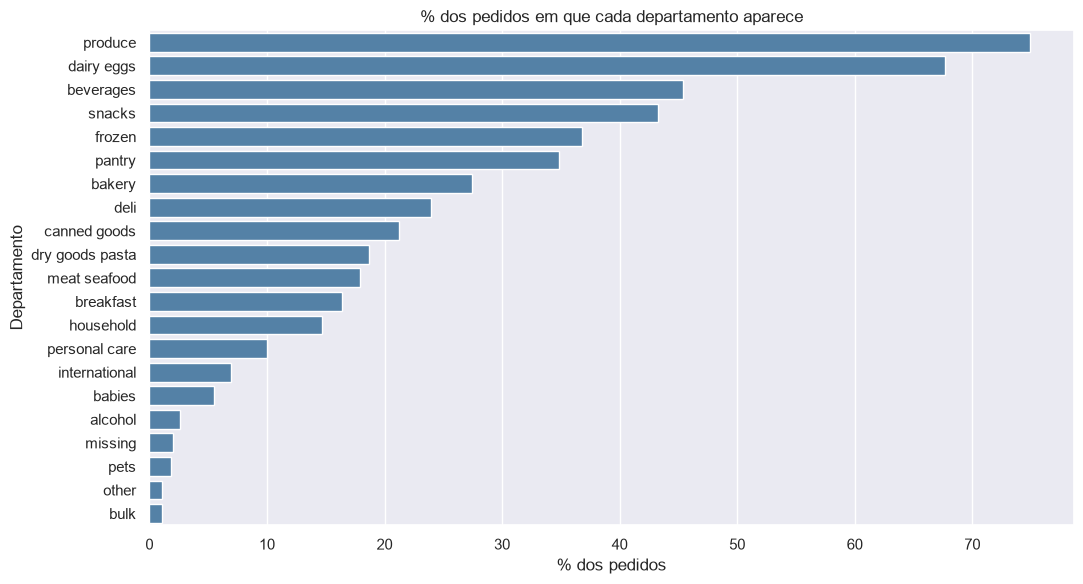

In [32]:
plt.figure(figsize=(11, 6))
sns.barplot(data=frequencia_departamentos, x="pct_pedidos", y="department", color="steelblue")
plt.title("% dos pedidos em que cada departamento aparece")
plt.xlabel("% dos pedidos")
plt.ylabel("Departamento")
plt.tight_layout()
plt.show()

### 9.2. Concentração da demanda

Quanto da demanda se concentra em poucos aisles? Isso é uma característica do dataset, independente de qualquer modelagem.

In [33]:
acum = frequencia_aisles["quantidade_pedidos"].cumsum() / frequencia_aisles["quantidade_pedidos"].sum()
for k in [5, 10, 20, 50]:
    if k <= len(acum):
        print(f"Os {k} aisles mais frequentes respondem por {100 * acum.iloc[k - 1]:.1f}% das ocorrências (pedido, aisle)")

Os 5 aisles mais frequentes respondem por 25.8% das ocorrências (pedido, aisle)
Os 10 aisles mais frequentes respondem por 38.5% das ocorrências (pedido, aisle)
Os 20 aisles mais frequentes respondem por 53.6% das ocorrências (pedido, aisle)
Os 50 aisles mais frequentes respondem por 82.0% das ocorrências (pedido, aisle)


## 10. Coocorrência entre aisles

Coocorrência significa observar quais aisles aparecem juntos em um mesmo pedido. Cada `aisle_id` conta uma vez por pedido.

1. montamos uma matriz esparsa `X` (pedidos × aisles), com 1 quando o aisle aparece no pedido;
2. a matriz de coocorrência é `C = Xᵀ · X`. A diagonal de `C` é a frequência de cada aisle e `C[i, j]` é o número de pedidos com `i` e `j` juntos.

**Por que não olhar só a contagem.** Aisles muito populares (frutas, vegetais) aparecem junto de quase tudo só porque aparecem em muitos pedidos. Por isso calculamos também, como **medidas descritivas**:

- `jaccard = C[i,j] / (f_i + f_j − C[i,j])`;
- `lift = C[i,j] · N / (f_i · f_j)`: quantas vezes mais os dois aparecem juntos do que o esperado se fossem independentes (`lift ≈ 1` indica apenas popularidade).

**Atenção:** coocorrência não significa proximidade física. Aqui ela apenas descreve o comportamento dos pedidos.

In [34]:
indice_aisle = pd.Index(aisles["aisle_id"])
nomes_aisles = aisles.set_index("aisle_id")["aisle"].to_dict()


def matriz_coocorrencia(oa_df):
    """Devolve (C, N): matriz aisle x aisle de pedidos em comum e número de pedidos."""
    codigos_pedido, _ = pd.factorize(oa_df["order_id"])
    colunas = indice_aisle.get_indexer(oa_df["aisle_id"])
    if (colunas < 0).any():
        raise ValueError("Há aisle_id sem cadastro em aisles.csv.")
    X = csr_matrix(
        (np.ones(len(oa_df), dtype=np.int32), (codigos_pedido, colunas)),
        shape=(codigos_pedido.max() + 1, len(indice_aisle)),
    )
    return (X.T @ X).toarray(), X.shape[0]


def tabela_coocorrencia(C, n_pedidos):
    """Converte a matriz em tabela de pares (triângulo superior) com contagem, jaccard e lift."""
    freq_aisle = np.diag(C).astype("float64")
    i, j = np.triu_indices_from(C, k=1)
    juntos = C[i, j].astype("float64")
    ativo = juntos > 0
    i, j, juntos = i[ativo], j[ativo], juntos[ativo]

    tabela = pd.DataFrame({
        "aisle_id_1": indice_aisle[i],
        "aisle_id_2": indice_aisle[j],
        "quantidade_pedidos_juntos": juntos.astype(int),
        "pedidos_aisle_1": freq_aisle[i].astype(int),
        "pedidos_aisle_2": freq_aisle[j].astype(int),
    })
    tabela["jaccard"] = juntos / (freq_aisle[i] + freq_aisle[j] - juntos)
    tabela["lift"] = juntos * n_pedidos / (freq_aisle[i] * freq_aisle[j])
    tabela["aisle_1"] = tabela["aisle_id_1"].map(nomes_aisles)
    tabela["aisle_2"] = tabela["aisle_id_2"].map(nomes_aisles)
    return tabela.sort_values("quantidade_pedidos_juntos", ascending=False).reset_index(drop=True)


# train sozinho e todos os pedidos (prior + train)
C_train, n_train = matriz_coocorrencia(oa[oa["eval_set"] == "train"])
coocorrencia_train = tabela_coocorrencia(C_train, n_train)

C_all, n_all = matriz_coocorrencia(oa)
coocorrencia = tabela_coocorrencia(C_all, n_all)

print(f"Pares de aisles com coocorrência > 0: train = {len(coocorrencia_train):,} | todos = {len(coocorrencia):,}")
print(f"Pedidos usados: train = {n_train:,} | todos = {n_all:,}")
print(f"Pares possíveis: {len(aisles) * (len(aisles) - 1) // 2:,}")

Pares de aisles com coocorrência > 0: train = 8,866 | todos = 8,911
Pedidos usados: train = 131,209 | todos = 3,346,083
Pares possíveis: 8,911


### 10.1. Pares mais frequentes (contagem bruta)

In [35]:
display(coocorrencia.head(30))

,aisle_id_1,aisle_id_2,quantidade_pedidos_juntos,pedidos_aisle_1,pedidos_aisle_2,jaccard,lift,aisle_1,aisle_2
0,24,83,1064513,1862949,1486803,0.465821,1.285977,fresh fruits,fresh vegetables
1,24,123,906577,1862949,1229500,0.414744,1.324378,fresh fruits,packaged vegetables fruits
2,83,123,786852,1486803,1229500,0.407811,1.440283,fresh vegetables,packaged vegetables fruits
3,24,120,628911,1862949,880330,0.297446,1.283156,fresh fruits,yogurt
4,24,84,548530,1862949,815345,0.257554,1.208355,fresh fruits,milk
5,21,24,519344,769098,1862949,0.245820,1.212856,packaged cheese,fresh fruits
6,83,120,482323,1486803,880330,0.255900,1.233036,fresh vegetables,yogurt
7,21,83,452520,769098,1486803,0.250929,1.324157,packaged cheese,fresh vegetables
8,120,123,428075,880330,1229500,0.254541,1.323374,yogurt,packaged vegetables fruits
9,83,84,417753,1486803,815345,0.221691,1.153085,fresh vegetables,milk


### 10.2. Pares com maior `lift`

O `lift` de um par raro é instável: poucos pedidos juntos podem gerar um `lift` alto por puro acaso. Para **exibir** o ranking, mostramos só pares com pelo menos `MIN_PEDIDOS_JUNTOS_EXIBICAO` pedidos em comum. Esse valor é só um filtro de leitura; **nenhuma linha é removida** das tabelas exportadas.

In [36]:
MIN_PEDIDOS_JUNTOS_EXIBICAO = 1000 if USAR_PRIOR else 50

ranking_lift = coocorrencia[
    coocorrencia["quantidade_pedidos_juntos"] >= MIN_PEDIDOS_JUNTOS_EXIBICAO
].sort_values("lift", ascending=False)

print(f"Pares com pelo menos {MIN_PEDIDOS_JUNTOS_EXIBICAO} pedidos juntos: {len(ranking_lift):,}")
display(ranking_lift.head(30))

Pares com pelo menos 1000 pedidos juntos: 6,263


,aisle_id_1,aisle_id_2,quantidade_pedidos_juntos,pedidos_aisle_1,pedidos_aisle_2,jaccard,lift,aisle_1,aisle_2
2670,28,62,8013,26212,26174,0.180583,39.080633,red wines,white wines
4826,62,134,2202,26174,10291,0.064268,27.354347,white wines,specialty wines champagnes
4870,28,134,2150,26212,10291,0.062586,26.669657,red wines,specialty wines champagnes
3286,27,28,5502,30877,26212,0.106655,22.746891,beers coolers,red wines
5483,124,134,1535,23705,10291,0.047288,21.054627,spirits,specialty wines champagnes
3501,27,62,4728,30877,26174,0.090362,19.575325,beers coolers,white wines
3966,62,124,3537,26174,23705,0.076324,19.074875,white wines,spirits
3757,27,124,4051,30877,23705,0.080169,18.519271,beers coolers,spirits
5248,27,134,1732,30877,10291,0.043919,18.238618,beers coolers,specialty wines champagnes
4113,28,124,3245,26212,23705,0.069528,17.474763,red wines,spirits


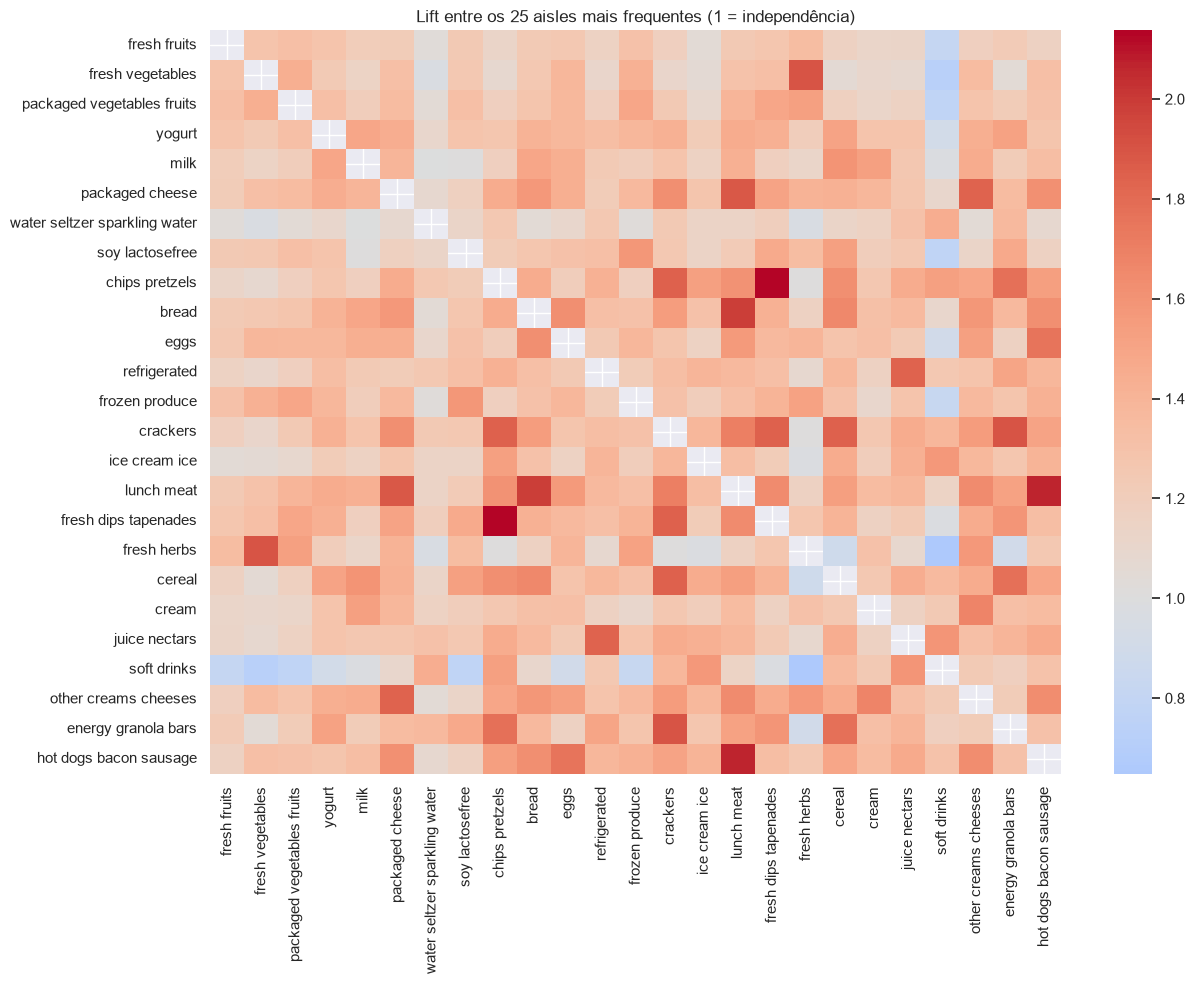

In [37]:
# lift entre os 25 aisles mais frequentes
ids_top = frequencia_aisles["aisle_id"].head(25).tolist()
pos = indice_aisle.get_indexer(ids_top)

sub = C_all[np.ix_(pos, pos)].astype("float64")
f = np.diag(C_all)[pos].astype("float64")
lift_sub = sub * n_all / np.outer(f, f)
np.fill_diagonal(lift_sub, np.nan)

rotulos = [nomes_aisles[a] for a in ids_top]
plt.figure(figsize=(13, 10))
sns.heatmap(pd.DataFrame(lift_sub, index=rotulos, columns=rotulos), cmap="coolwarm", center=1.0)
plt.title("Lift entre os 25 aisles mais frequentes (1 = independência)")
plt.tight_layout()
plt.show()

### 10.3. Distribuição do `lift` e da contagem

Visão geral dos pares com suporte mínimo de exibição: quantos têm `lift` acima de 1 (ocorrem juntos mais do que o acaso) e abaixo de 1.

,lift
count,6263.000
mean,1.504
std,1.142
min,0.340
5%,0.838
25%,1.161
50%,1.356
75%,1.595
95%,2.359
max,39.081


  lift >= 0.5: 99.7% dos pares
  lift >= 1.0: 88.6% dos pares
  lift >= 1.5: 32.8% dos pares
  lift >= 2.0: 8.9% dos pares
  lift >= 3.0: 2.5% dos pares


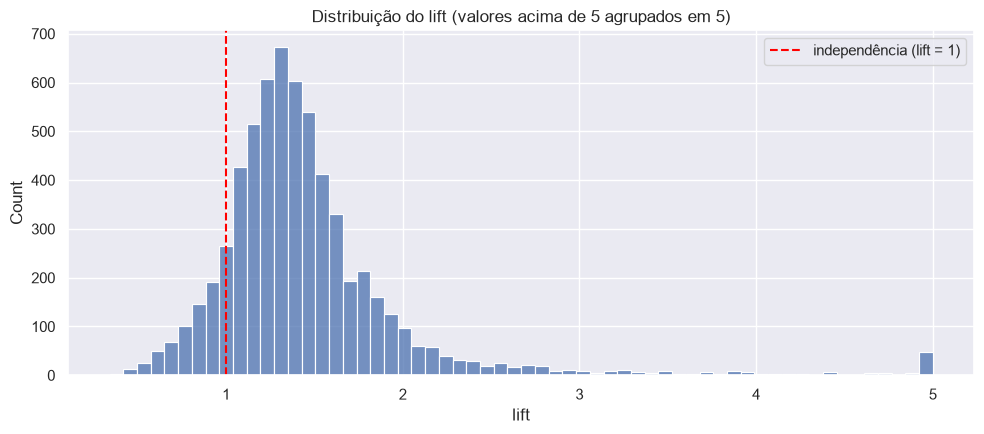

In [38]:
display(ranking_lift["lift"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(3).to_frame("lift"))
for corte in [0.5, 1.0, 1.5, 2.0, 3.0]:
    print(f"  lift >= {corte}: {100 * (ranking_lift['lift'] >= corte).mean():.1f}% dos pares")

plt.figure(figsize=(10, 4.5))
sns.histplot(ranking_lift["lift"].clip(upper=5), bins=60)
plt.axvline(1.0, color="red", linestyle="--", label="independência (lift = 1)")
plt.title("Distribuição do lift (valores acima de 5 agrupados em 5)")
plt.xlabel("lift")
plt.legend()
plt.tight_layout()
plt.show()

### 10.4. Coocorrência entre departamentos

A mesma ideia, agora no nível de departamento: em quantos pedidos cada par de departamentos aparece junto.

In [39]:
codigos_pedido, _ = pd.factorize(od["order_id"])
ids_dep = departamentos["department_id"].tolist()
col_dep = pd.Index(ids_dep).get_indexer(od["department_id"])
Xd = csr_matrix((np.ones(len(od), dtype=np.int32), (codigos_pedido, col_dep)),
                shape=(codigos_pedido.max() + 1, len(ids_dep)))
Cd = (Xd.T @ Xd).toarray()
fd = np.diag(Cd).astype("float64")
nd = Xd.shape[0]

nomes_dep = departamentos.set_index("department_id")["department"].to_dict()
i, j = np.triu_indices_from(Cd, k=1)
coocorrencia_departamentos = pd.DataFrame({
    "department_id_1": np.array(ids_dep)[i],
    "department_id_2": np.array(ids_dep)[j],
    "quantidade_pedidos_juntos": Cd[i, j],
})
coocorrencia_departamentos["pct_pedidos"] = (100 * coocorrencia_departamentos["quantidade_pedidos_juntos"] / nd).round(2)
coocorrencia_departamentos["lift"] = (Cd[i, j] * nd / (fd[i] * fd[j])).round(3)
coocorrencia_departamentos["departamento_1"] = coocorrencia_departamentos["department_id_1"].map(nomes_dep)
coocorrencia_departamentos["departamento_2"] = coocorrencia_departamentos["department_id_2"].map(nomes_dep)
coocorrencia_departamentos = coocorrencia_departamentos.sort_values("quantidade_pedidos_juntos", ascending=False).reset_index(drop=True)

display(coocorrencia_departamentos.head(15))

,department_id_1,department_id_2,quantidade_pedidos_juntos,pct_pedidos,lift,departamento_1,departamento_2
0,4,16,1841091,55.02,0.000,produce,dairy eggs
1,4,19,1128643,33.73,0.000,produce,snacks
2,4,7,1117258,33.39,0.000,produce,beverages
3,16,19,1079502,32.26,0.000,dairy eggs,snacks
4,7,16,1074107,32.10,-0.000,beverages,dairy eggs
5,1,4,999677,29.88,-0.000,frozen,produce
6,4,13,961552,28.74,0.000,produce,pantry
7,1,16,950433,28.40,0.001,frozen,dairy eggs
8,13,16,902418,26.97,0.000,pantry,dairy eggs
9,7,19,767732,22.94,0.000,beverages,snacks


### 10.5. O `train` e o conjunto completo contam a mesma história?

In [40]:
if USAR_PRIOR:
    comparacao = coocorrencia_train.merge(
        coocorrencia, on=["aisle_id_1", "aisle_id_2"], how="inner", suffixes=("_train", "_all")
    )
    comparacao["taxa_train"] = comparacao["quantidade_pedidos_juntos_train"] / n_train
    comparacao["taxa_all"] = comparacao["quantidade_pedidos_juntos_all"] / n_all

    print("Spearman da taxa de coocorrência (train x todos):",
          round(comparacao["taxa_train"].corr(comparacao["taxa_all"], method="spearman"), 4))

    k = min(50, len(coocorrencia_train), len(coocorrencia))
    top_train = set(map(tuple, coocorrencia_train.nlargest(k, "quantidade_pedidos_juntos")[["aisle_id_1", "aisle_id_2"]].to_numpy()))
    top_all = set(map(tuple, coocorrencia.nlargest(k, "quantidade_pedidos_juntos")[["aisle_id_1", "aisle_id_2"]].to_numpy()))
    print(f"Pares em comum entre os {k} mais frequentes:", len(top_train & top_all), "de", k)

    print(f"Pares observados: train = {len(coocorrencia_train):,} | todos = {len(coocorrencia):,} "
          f"(o prior revela {len(coocorrencia) - len(coocorrencia_train):,} pares que o train sozinho nunca viu)")
else:
    print("USAR_PRIOR = False: comparação ignorada.")

Spearman da taxa de coocorrência (train x todos): 0.9937
Pares em comum entre os 50 mais frequentes: 47 de 50
Pares observados: train = 8,866 | todos = 8,911 (o prior revela 45 pares que o train sozinho nunca viu)


## 11. Análise temporal dos pedidos

O dataset traz o dia da semana (`order_dow`) e a hora do dia (`order_hour_of_day`) em que o pedido foi realizado. Elas descrevem a **demanda** (quando os clientes fazem pedidos), e não o horário em que a coleta ocorreria.

> O dataset não informa a qual dia da semana corresponde cada valor de `order_dow` (0 a 6). Se o relatório precisar dos nomes dos dias, isso deve ser registrado como suposição.

,horario,quantidade_pedidos,pct
0,0,22224,0.66
1,1,12103,0.36
2,2,7375,0.22
3,3,5343,0.16
4,4,5393,0.16
5,5,9374,0.28
6,6,29913,0.89
7,7,90032,2.69
8,8,174664,5.22
9,9,252529,7.55


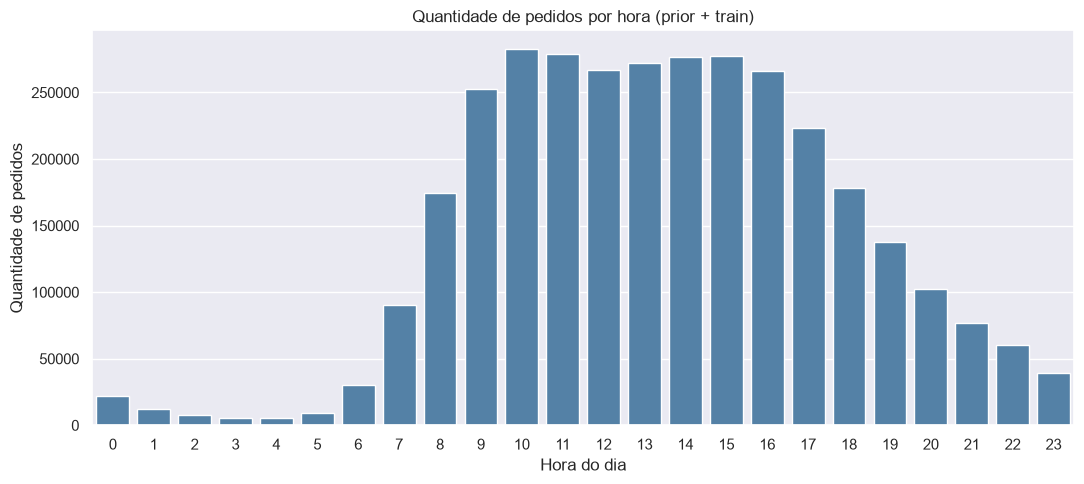

In [41]:
pedidos_por_hora = pedidos.groupby("horario").size().rename("quantidade_pedidos").reset_index()
pedidos_por_hora["pct"] = (100 * pedidos_por_hora["quantidade_pedidos"] / len(pedidos)).round(2)
display(pedidos_por_hora)

plt.figure(figsize=(11, 5))
sns.barplot(data=pedidos_por_hora, x="horario", y="quantidade_pedidos", color="steelblue")
plt.title("Quantidade de pedidos por hora (prior + train)")
plt.xlabel("Hora do dia")
plt.ylabel("Quantidade de pedidos")
plt.tight_layout()
plt.show()

In [42]:
pedidos_por_dia = pedidos.groupby("dia_semana").size().rename("quantidade_pedidos").reset_index().sort_values("dia_semana")
pedidos_por_dia["pct"] = (100 * pedidos_por_dia["quantidade_pedidos"] / len(pedidos)).round(2)
display(pedidos_por_dia)

,dia_semana,quantidade_pedidos,pct
0,0,585237,17.49
1,1,576377,17.23
2,2,458074,13.69
3,3,428087,12.79
4,4,417171,12.47
5,5,443388,13.25
6,6,437749,13.08


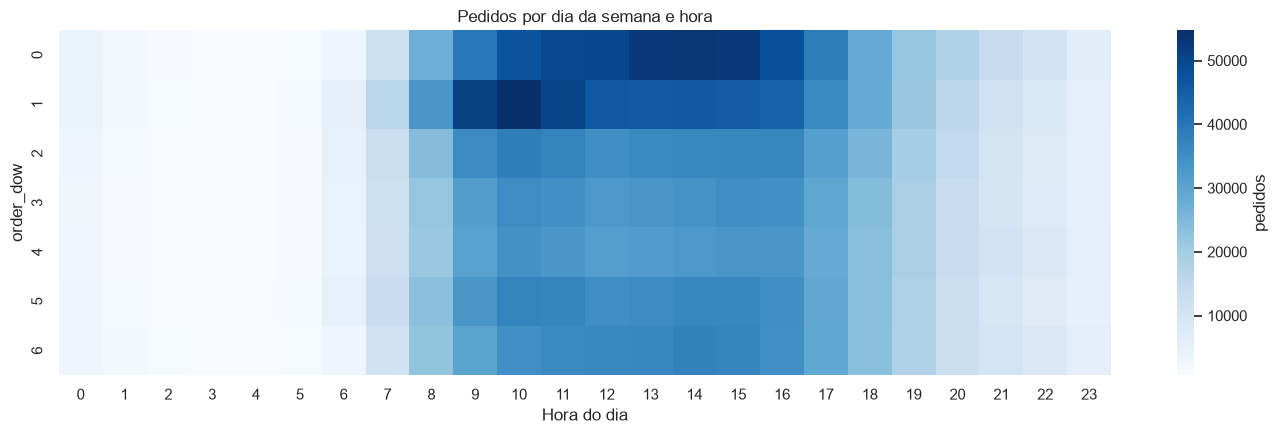

In [43]:
dia_hora = pedidos.groupby(["dia_semana", "horario"]).size().unstack("horario").fillna(0)

plt.figure(figsize=(14, 4.5))
sns.heatmap(dia_hora, cmap="Blues", cbar_kws={"label": "pedidos"})
plt.title("Pedidos por dia da semana e hora")
plt.xlabel("Hora do dia")
plt.ylabel("order_dow")
plt.tight_layout()
plt.show()

### 11.1. O tamanho do pedido varia com o horário e o dia?

horario,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
quantidade_itens,10.26,10.03,9.85,10.06,10.33,9.80,10.12,10.31,10.23,10.10,10.18,10.24,10.24,10.22,10.16,10.03,9.94,9.79,9.60,9.59,9.97,10.87,11.04,10.72
quantidade_aisles,7.30,7.15,7.09,7.25,7.36,7.05,7.27,7.39,7.28,7.13,7.20,7.30,7.36,7.36,7.33,7.27,7.23,7.18,7.09,7.06,7.21,7.68,7.75,7.56
quantidade_departamentos,4.73,4.67,4.65,4.76,4.79,4.60,4.71,4.78,4.69,4.61,4.65,4.73,4.78,4.79,4.78,4.77,4.76,4.75,4.73,4.71,4.74,4.92,4.94,4.85


,quantidade_itens,quantidade_aisles,quantidade_departamentos
dia_semana,,,
0,11.16,8.02,5.15
1,10.19,7.23,4.69
2,9.56,6.89,4.54
3,9.34,6.77,4.49
4,9.45,6.84,4.51
5,9.89,7.11,4.64
6,10.75,7.80,5.05


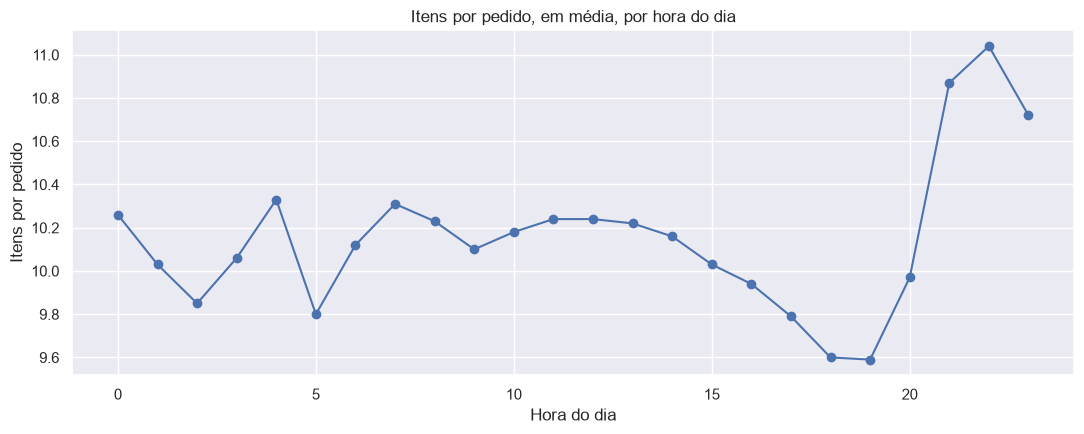

In [44]:
tam_hora = pedidos.groupby("horario")[["quantidade_itens", "quantidade_aisles", "quantidade_departamentos"]].mean().round(2)
display(tam_hora.T)

tam_dia = pedidos.groupby("dia_semana")[["quantidade_itens", "quantidade_aisles", "quantidade_departamentos"]].mean().round(2)
display(tam_dia)

fig, ax = plt.subplots(figsize=(11, 4.5))
tam_hora["quantidade_itens"].plot(ax=ax, marker="o")
ax.set_title("Itens por pedido, em média, por hora do dia")
ax.set_xlabel("Hora do dia")
ax.set_ylabel("Itens por pedido")
plt.tight_layout()
plt.show()

## 12. Análise dos clientes

O dataset é organizado por clientes (`user_id`). Esta seção descreve o comportamento deles, o que ajuda a entender o peso de clientes muito ativos nas análises agregadas.

Pedidos por cliente (todas as divisões):


,pedidos
count,206209.00
mean,16.59
std,16.65
min,4.00
5%,4.00
25%,6.00
50%,10.00
75%,20.00
95%,52.00
max,100.00



Os 10% de clientes mais ativos respondem por 40.4% dos itens


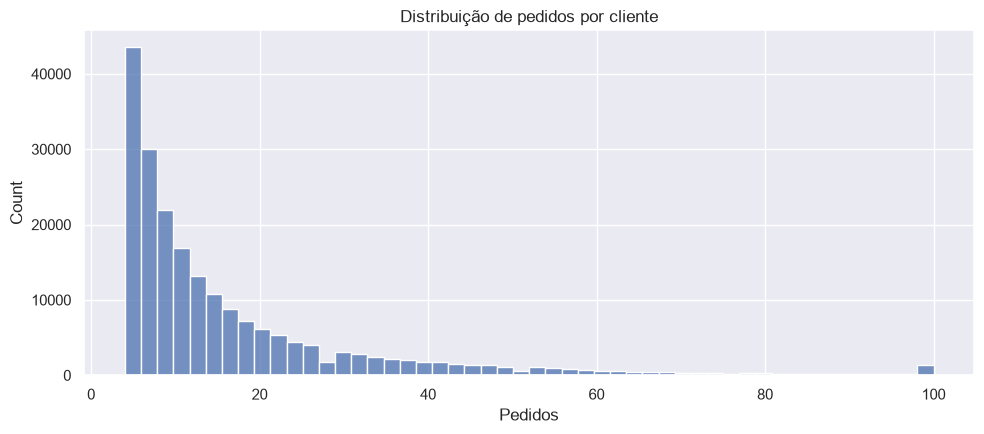

In [45]:
pedidos_por_cliente = orders.groupby("user_id").size().rename("pedidos")
print("Pedidos por cliente (todas as divisões):")
display(pedidos_por_cliente.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(2).to_frame("pedidos"))

itens_por_cliente = pedidos.groupby("user_id")["quantidade_itens"].sum().rename("itens")
cumul = itens_por_cliente.sort_values(ascending=False).cumsum() / itens_por_cliente.sum()
print(f"\nOs 10% de clientes mais ativos respondem por {100 * cumul.iloc[int(len(cumul) * 0.10) - 1]:.1f}% dos itens")

plt.figure(figsize=(10, 4.5))
sns.histplot(pedidos_por_cliente, bins=50)
plt.title("Distribuição de pedidos por cliente")
plt.xlabel("Pedidos")
plt.tight_layout()
plt.show()

### 12.1. Intervalo entre pedidos

In [46]:
intervalo = orders["days_since_prior_order"].dropna()
display(intervalo.describe(percentiles=[0.25, 0.5, 0.75, 0.95]).round(2).to_frame("dias"))
print(f"Pedidos com o valor máximo (30, que no dataset equivale a '30 dias ou mais'): "
      f"{100 * (intervalo == 30).mean():.1f}%")

,dias
count,3214874.00
mean,11.11
std,9.21
min,0.00
25%,4.00
50%,7.00
75%,15.00
95%,30.00
max,30.00


Pedidos com o valor máximo (30, que no dataset equivale a '30 dias ou mais'): 11.5%


## 13. Exportação dos dados curados

Vamos salvar os resultados principais em CSV. Todos os arquivos são **neutros**: descrevem os dados e não pressupõem nenhuma modelagem. Os CSVs originais não são alterados.

| Arquivo | Conteúdo |
|---|---|
| `dados_integrados_train.csv` | uma linha por produto em cada pedido `train`, com nomes de produto, aisle e departamento |
| `catalogo_aisles_departamentos.csv` | cada aisle com seu departamento e número de produtos cadastrados |
| `pedidos_train_listas.csv` | uma linha por pedido `train`, com as listas de `aisle_id` e `department_id` (separadas por `;`) |
| `pedidos_resumo_all.csv` | resumo de cada pedido `prior` + `train` (itens, aisles, departamentos, dia, hora); arquivo grande |
| `frequencia_aisles.csv` | frequência dos aisles (total, `prior` e `train`) |
| `frequencia_departamentos.csv` | frequência dos departamentos (total, `prior` e `train`) |
| `coocorrencia_aisles_train.csv` | coocorrência de aisles no `train`, com `jaccard` e `lift` |
| `coocorrencia_aisles_prior_train.csv` | coocorrência de aisles em `prior` + `train`, com `jaccard` e `lift` |
| `coocorrencia_departamentos.csv` | coocorrência de departamentos em `prior` + `train` |
| `produtos_mais_pedidos.csv` | frequência e taxa de recompra de cada produto |

In [47]:
PASTA_SAIDA = Path("../dados/curados")
PASTA_SAIDA.mkdir(exist_ok=True)

EXPORTAR_PEDIDOS_RESUMO = True    # ~3,3 milhões de linhas; coloque False se não precisar
EXPORTAR_DADOS_INTEGRADOS = True  # ~1,4 milhão de linhas


def juntar(lista):
    return ";".join(str(x) for x in lista)


catalogo = quantidade_por_aisle[["aisle_id", "aisle", "department_id", "department", "quantidade_produtos"]].sort_values("aisle_id")
catalogo.to_csv(PASTA_SAIDA / "catalogo_aisles_departamentos.csv", index=False)

pedidos_train_export = pedidos_train.copy()
pedidos_train_export["aisles"] = pedidos_train_export["aisles"].apply(juntar)
pedidos_train_export["departamentos"] = pedidos_train_export["departamentos"].apply(juntar)
pedidos_train_export.to_csv(PASTA_SAIDA / "pedidos_train_listas.csv", index=False)

frequencia_aisles.to_csv(PASTA_SAIDA / "frequencia_aisles.csv", index=False)
frequencia_departamentos.to_csv(PASTA_SAIDA / "frequencia_departamentos.csv", index=False)
coocorrencia_train.to_csv(PASTA_SAIDA / "coocorrencia_aisles_train.csv", index=False)
coocorrencia_departamentos.to_csv(PASTA_SAIDA / "coocorrencia_departamentos.csv", index=False)
produtos_mais_pedidos.to_csv(PASTA_SAIDA / "produtos_mais_pedidos.csv", index=False)

if USAR_PRIOR:
    coocorrencia.to_csv(PASTA_SAIDA / "coocorrencia_aisles_prior_train.csv", index=False)

if EXPORTAR_DADOS_INTEGRADOS:
    dados.to_csv(PASTA_SAIDA / "dados_integrados_train.csv", index=False)

if EXPORTAR_PEDIDOS_RESUMO:
    pedidos.drop(columns=["itens_por_aisle"]).to_csv(PASTA_SAIDA / "pedidos_resumo_all.csv", index=False)

print("Arquivos exportados em:", PASTA_SAIDA.resolve())
for arq in sorted(PASTA_SAIDA.glob("*.csv")):
    print(f"  {arq.name:45s} {arq.stat().st_size / 1e6:8.1f} MB")

Arquivos exportados em: C:\Users\yasmin\Downloads\grafos5\dados_curados
  catalogo_aisles_departamentos.csv                  0.0 MB
  coocorrencia_aisles_prior_train.csv                0.9 MB
  coocorrencia_aisles_train.csv                      0.8 MB
  coocorrencia_departamentos.csv                     0.0 MB
  dados_integrados_train.csv                       126.1 MB
  frequencia_aisles.csv                              0.0 MB
  frequencia_departamentos.csv                       0.0 MB
  pedidos_resumo_all.csv                           109.4 MB
  pedidos_train_listas.csv                           9.2 MB
  produtos_mais_pedidos.csv                          3.4 MB


## 14. Conclusões da curadoria

Ao concluir a execução, registre aqui os números observados. A lista abaixo organiza o que costuma entrar na seção de dados do relatório.

### Checklist de pontos a registrar

**Estrutura e qualidade**

1. Quantidade de registros e colunas de cada arquivo original (incluindo o `prior`).
2. Resultado das verificações de valores ausentes, duplicidades e integridade dos identificadores, no `train` **e** no `prior`.
3. Confirmação de que `prior` e `train` não compartilham pedidos e de que o último pedido de cada cliente é `train` ou `test`.
4. Quantidade de pedidos com itens disponíveis (`prior` + `train`) e o que ficou de fora (`test`, sem itens).
5. Confirmação de que cada aisle pertence a um único departamento.

**Caracterização dos pedidos**

6. Distribuição de itens, aisles e departamentos por pedido (seção 8).
7. Relação entre itens e aisles distintos por pedido (seção 8.3).
8. Se o `train` é representativo do `prior` (seções 8.5 e 10.5).
9. Aisles, departamentos e produtos mais frequentes; concentração da demanda (seções 7.3, 9 e 9.2).
10. Principais pares de aisles e de departamentos que aparecem juntos (seção 10).
11. Distribuição dos pedidos por dia e horário, e variação do tamanho do pedido (seções 11 e 11.1).
12. Perfil dos clientes e intervalo entre pedidos (seção 12).

### Limitações do dataset

- Os pedidos `test` não têm itens e ficam fora da análise.
- Os pedidos do `prior` são o histórico dos mesmos clientes do `train`; clientes muito ativos pesam mais nas medidas agregadas.
- O dataset **não traz layout físico, coordenadas, dimensões da loja nem distâncias**: `aisle` e `department` são categorias de classificação, não posições.
- `add_to_cart_order` é a ordem de inclusão no carrinho online, **não** a ordem de coleta.
- `order_dow` não informa a qual dia da semana cada valor corresponde, e `order_hour_of_day` é o horário do pedido, não da coleta.
- Os aisles e departamentos `missing` e `other` reúnem produtos sem classificação definida, o que pode misturar itens sem relação entre si.
- `lift` e `jaccard` descrevem a tendência de dois aisles aparecerem juntos nos pedidos, **não** a proximidade entre eles.
- Os dados são de uma operação real de supermercado online dos EUA; os padrões podem não se transferir para outras realidades.

### Próxima etapa

Os arquivos de `dados_curados/` ficam disponíveis para o grupo definir livremente a modelagem (vértices, arestas, pesos, layout) e os algoritmos de roteirização.